# UNSW-NB15 IDS: Complete Model Training Pipeline

This notebook trains and evaluates the six requested models **without building an ensemble**:

- Random Forest
- XGBoost
- LightGBM
- CatBoost
- MLP
- SVM

Pipeline:

1. Load official UNSW-NB15 train/test files
2. Clean and one-hot encode the data
3. Use the exact 19 selected features
4. Run leakage/sanity checks
5. Hyperparameter tuning with cross-validation
6. Re-evaluate each tuned model with 5-fold Stratified CV
7. Generate out-of-fold validation scores
8. Optimize the classification threshold using validation/OoF predictions
9. Compare all tuned models
10. Optionally evaluate the frozen models + thresholds once on the untouched official test set

**No ensemble is created. No models are saved to disk.**

### SVM runtime decision

The previous RBF SVM was extremely slow inside repeated cross-validation. This notebook therefore uses **LinearSVC** as the SVM implementation. It is still an SVM classifier, uses `decision_function()` for scoring, supports class weighting, and is dramatically more practical for UNSW-NB15.

If you specifically need the RBF SVC later, run it separately after the other experiments finish.

In [1]:
# 1. Imports and configuration

import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    precision_recall_curve, roc_curve
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

RANDOM_STATE = 42

TRAIN_PATH = "UNSW_NB15_training-set.csv"
TEST_PATH = "UNSW_NB15_testing-set.csv"

TARGET = "label"

# Exact selected feature list from the previous feature-selection work.
SELECTED_FEATURES = [
    "ct_dst_src_ltm", "sttl", "sbytes", "smean", "dmean", "dttl",
    "dbytes", "ct_state_ttl", "service_none", "ct_dst_sport_ltm",
    "dload", "proto_udp", "sloss", "state_int", "proto_tcp",
    "service_http", "tcprtt", "swin", "response_body_len"
]

N_TUNING_FOLDS = 3
N_EVAL_FOLDS = 5

print("Configuration loaded.")
print("Selected feature count:", len(SELECTED_FEATURES))

Configuration loaded.
Selected feature count: 19


In [2]:
# 2. Locate the dataset files

print("Current working directory:", os.getcwd())

if not os.path.exists(TRAIN_PATH):
    raise FileNotFoundError(
        f"Could not find {TRAIN_PATH}. Put the CSV in the notebook working directory "
        "or change TRAIN_PATH above."
    )

if not os.path.exists(TEST_PATH):
    raise FileNotFoundError(
        f"Could not find {TEST_PATH}. Put the CSV in the notebook working directory "
        "or change TEST_PATH above."
    )

print("Train:", TRAIN_PATH)
print("Test :", TEST_PATH)

Current working directory: C:\Users\aksha\OneDrive\Pictures\Documents\Dummy
Train: UNSW_NB15_training-set.csv
Test : UNSW_NB15_testing-set.csv


In [3]:
# 3. Load official UNSW-NB15 train/test files

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)

display(train_df.head())

Train shape: (175341, 45)
Test shape : (82332, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [4]:
# 4. Basic dataset checks

print("Train columns:", len(train_df.columns))
print("Test columns :", len(test_df.columns))

print("\nTarget distribution:")
display(train_df[TARGET].value_counts(dropna=False).to_frame("count"))

print("\nMissing values in train:")
display(train_df.isna().sum().sort_values(ascending=False).head(15).to_frame("missing"))

print("\nDuplicate rows:")
print("Train duplicates:", train_df.duplicated().sum())
print("Test duplicates :", test_df.duplicated().sum())

Train columns: 45
Test columns : 45

Target distribution:


,count
label,
1,119341
0,56000



Missing values in train:


,missing
id,0
dwin,0
synack,0
ackdat,0
smean,0
dmean,0
trans_depth,0
response_body_len,0
ct_srv_src,0
ct_state_ttl,0



Duplicate rows:
Train duplicates: 0
Test duplicates : 0


In [5]:
# 5. Clean and one-hot encode

def prepare_dataframe(df):
    out = df.copy()

    # Remove identifier and attack-category target information.
    out = out.drop(columns=["id", "attack_cat"], errors="ignore")

    cat_cols = [c for c in ["proto", "service", "state"] if c in out.columns]

    for col in cat_cols:
        out[col] = (
            out[col]
            .astype(str)
            .str.strip()
            .str.lower()
            .replace("-", "none")
        )

    X = pd.get_dummies(
        out.drop(columns=[TARGET]),
        columns=cat_cols,
        drop_first=False
    )

    y = out[TARGET].astype(int)

    return X, y

X_train_all, y_train = prepare_dataframe(train_df)
X_test_all, y_test = prepare_dataframe(test_df)

# Force identical feature columns/order between train and official test.
X_test_all = X_test_all.reindex(columns=X_train_all.columns, fill_value=0)

print("Encoded train shape:", X_train_all.shape)
print("Encoded test shape :", X_test_all.shape)

Encoded train shape: (175341, 194)
Encoded test shape : (82332, 194)


In [6]:
# 6. Apply the exact 19 selected features

missing_selected = [c for c in SELECTED_FEATURES if c not in X_train_all.columns]

if missing_selected:
    raise ValueError(f"Selected features missing after encoding: {missing_selected}")

X_selected = X_train_all[SELECTED_FEATURES].copy()
X_test_selected = X_test_all[SELECTED_FEATURES].copy()

print("Final selected feature count:", X_selected.shape[1])
print(SELECTED_FEATURES)

Final selected feature count: 19
['ct_dst_src_ltm', 'sttl', 'sbytes', 'smean', 'dmean', 'dttl', 'dbytes', 'ct_state_ttl', 'service_none', 'ct_dst_sport_ltm', 'dload', 'proto_udp', 'sloss', 'state_int', 'proto_tcp', 'service_http', 'tcprtt', 'swin', 'response_body_len']


In [7]:
# 7. Leakage and sanity checks

assert TARGET not in X_selected.columns
assert "attack_cat" not in X_selected.columns
assert "id" not in X_selected.columns

# Check exact feature-row overlap between train and official test.
shared_rows = pd.merge(
    X_selected.drop_duplicates(),
    X_test_selected.drop_duplicates(),
    how="inner"
).shape[0]

print("Exact shared feature rows:", shared_rows)
print("Target leakage check: passed")
print("Selected-feature existence check: passed")
print("Training class distribution:")
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())

Exact shared feature rows: 2144
Target leakage check: passed
Selected-feature existence check: passed
Training class distribution:


,proportion
label,
1,0.680622
0,0.319378


## 8. Hyperparameter tuning strategy

Tuning is performed **only on the training set** using 3-fold Stratified CV.

The official UNSW-NB15 test set is not used for:

- hyperparameter selection
- feature selection
- threshold selection

The tuning metric is **F1**, because this is a binary intrusion-detection problem where both missed attacks and false alerts matter.

After tuning, the selected estimator is independently evaluated with a fresh 5-fold CV procedure and out-of-fold predictions.

In [8]:
# 9. Model definitions and tuning spaces

negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_pos_weight = negative_count / positive_count

models_and_spaces = {

    "Random Forest": (
        RandomForestClassifier(
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        {
            "n_estimators": [150, 250, 350],
            "max_depth": [None, 15, 20, 30],
            "min_samples_split": [2, 5, 10],
            "min_samples_leaf": [1, 2, 4],
            "max_features": ["sqrt", "log2", 0.7]
        },
        10
    ),

    "XGBoost": (
        XGBClassifier(
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        {
            "n_estimators": [150, 250, 350, 500],
            "max_depth": [3, 5, 7, 9],
            "learning_rate": [0.03, 0.05, 0.1, 0.2],
            "subsample": [0.7, 0.8, 1.0],
            "colsample_bytree": [0.7, 0.8, 1.0],
            "min_child_weight": [1, 3, 5],
            "gamma": [0, 0.1, 0.3],
            "scale_pos_weight": [scale_pos_weight]
        },
        15
    ),

    "LightGBM": (
        LGBMClassifier(
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=-1
        ),
        {
            "n_estimators": [150, 250, 350, 500],
            "learning_rate": [0.03, 0.05, 0.1],
            "num_leaves": [15, 31, 63],
            "max_depth": [-1, 10, 20],
            "min_child_samples": [10, 20, 40],
            "subsample": [0.7, 0.8, 1.0],
            "colsample_bytree": [0.7, 0.8, 1.0]
        },
        12
    ),

    "CatBoost": (
        CatBoostClassifier(
            auto_class_weights="Balanced",
            random_seed=RANDOM_STATE,
            verbose=False,
            thread_count=-1
        ),
        {
            "iterations": [200, 300, 500],
            "depth": [5, 6, 7, 8],
            "learning_rate": [0.03, 0.05, 0.1],
            "l2_leaf_reg": [1, 3, 5, 7],
            "border_count": [64, 128, 254]
        },
        10
    ),

    "MLP": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", MLPClassifier(
                max_iter=100,
                early_stopping=True,
                validation_fraction=0.1,
                n_iter_no_change=10,
                random_state=RANDOM_STATE
            ))
        ]),
        {
            "model__hidden_layer_sizes": [(64,), (128,), (128, 64)],
            "model__alpha": [1e-5, 1e-4, 1e-3, 1e-2],
            "model__learning_rate_init": [1e-4, 5e-4, 1e-3],
            "model__batch_size": [128, 256, 512]
        },
        8
    ),

    # LinearSVC is used deliberately instead of RBF SVC because the
    # previous RBF implementation took an impractical amount of time
    # inside repeated CV on UNSW-NB15.
    "SVM": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", LinearSVC(
                class_weight="balanced",
                max_iter=5000,
                random_state=RANDOM_STATE
            ))
        ]),
        {
            "model__C": [0.001, 0.01, 0.1, 1, 10, 100]
        },
        6
    )
}

print("Models:", list(models_and_spaces.keys()))

Models: ['Random Forest', 'XGBoost', 'LightGBM', 'CatBoost', 'MLP', 'SVM']


In [9]:
# 10. Hyperparameter tuning

tuning_cv = StratifiedKFold(
    n_splits=N_TUNING_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

tuned_models = {}
tuning_rows = []

for name, (estimator, param_space, n_iter) in models_and_spaces.items():

    print("\n" + "=" * 80)
    print("TUNING:", name)
    print("=" * 80)

    start = time.time()

    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=param_space,
        n_iter=n_iter,
        scoring="f1",
        cv=tuning_cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=True,
        verbose=1
    )

    search.fit(X_selected, y_train)

    elapsed = time.time() - start

    tuned_models[name] = search.best_estimator_

    tuning_rows.append({
        "Model": name,
        "Best_CV_F1": search.best_score_,
        "Tuning_Time_min": elapsed / 60,
        "Best_Params": search.best_params_
    })

    print("Best CV F1:", round(search.best_score_, 6))
    print("Time:", round(elapsed / 60, 2), "minutes")
    print("Best parameters:")
    print(search.best_params_)

tuning_summary = pd.DataFrame(tuning_rows)
display(tuning_summary)


TUNING: Random Forest
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best CV F1: 0.967507
Time: 1.7 minutes
Best parameters:
{'n_estimators': 150, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None}

TUNING: XGBoost
Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best CV F1: 0.9637
Time: 0.54 minutes
Best parameters:
{'subsample': 0.8, 'scale_pos_weight': 0.469243596081816, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 7, 'learning_rate': 0.1, 'gamma': 0.1, 'colsample_bytree': 1.0}

TUNING: LightGBM
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best CV F1: 0.964655
Time: 0.58 minutes
Best parameters:
{'subsample': 0.8, 'num_leaves': 63, 'n_estimators': 500, 'min_child_samples': 10, 'max_depth': 10, 'learning_rate': 0.05, 'colsample_bytree': 0.7}

TUNING: CatBoost
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best CV F1: 0.963058
Time: 1.81 minutes
Best parameters:
{'learning_rate'

,Model,Best_CV_F1,Tuning_Time_min,Best_Params
0,Random Forest,0.967507,1.703367,"{'n_estimators': 150, 'min_samples_split': 2, ..."
1,XGBoost,0.963700,0.540102,"{'subsample': 0.8, 'scale_pos_weight': 0.46924..."
2,LightGBM,0.964655,0.576452,"{'subsample': 0.8, 'num_leaves': 63, 'n_estima..."
3,CatBoost,0.963058,1.810734,"{'learning_rate': 0.1, 'l2_leaf_reg': 5, 'iter..."
4,MLP,0.958685,8.514251,"{'model__learning_rate_init': 0.001, 'model__h..."
5,SVM,0.946744,0.257539,{'model__C': 1}


## 11. Fresh 5-fold evaluation of the tuned models

The tuning stage has selected hyperparameters.

Now each tuned model is evaluated again using **5-fold Stratified CV**.

This stage produces:

- fold-level metrics
- out-of-fold scores for every training record
- a clean basis for threshold optimization

For probability-based models, `predict_proba()[:, 1]` is used.

For SVM, `decision_function()` is used. This avoids the expensive probability calibration that made the previous RBF SVM take roughly 36+ minutes.

In [10]:
# 12. Metric helper

def get_score(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

def metrics_from_scores(y_true, scores, threshold=0.5):
    y_pred = (scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, scores),
        "FPR": fp / (fp + tn) if (fp + tn) else 0,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "TP": tp
    }

In [11]:
# 13. Fresh 5-fold CV + out-of-fold predictions

evaluation_cv = StratifiedKFold(
    n_splits=N_EVAL_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = {}
oof_scores = {}
fold_rows = []

for name, tuned_model in tuned_models.items():

    print("\n" + "=" * 80)
    print("5-FOLD EVALUATION:", name)
    print("=" * 80)

    start_total = time.time()
    scores_oof = np.zeros(len(y_train))

    for fold, (train_idx, val_idx) in enumerate(
        evaluation_cv.split(X_selected, y_train), 1
    ):

        fold_start = time.time()

        X_tr = X_selected.iloc[train_idx]
        X_va = X_selected.iloc[val_idx]
        y_tr = y_train.iloc[train_idx]
        y_va = y_train.iloc[val_idx]

        model = clone(tuned_model)

        # MLP is balanced using random oversampling inside the training fold only.
        # Other models already use class weighting / scale_pos_weight.
        if name == "MLP":
            rng = np.random.default_rng(RANDOM_STATE + fold)

            y_array = y_tr.to_numpy()
            classes, counts = np.unique(y_array, return_counts=True)
            max_count = counts.max()

            chosen_indices = []
            for cls, count in zip(classes, counts):
                idx = np.flatnonzero(y_array == cls)
                chosen = (
                    rng.choice(idx, size=max_count, replace=True)
                    if count < max_count else idx
                )
                chosen_indices.extend(chosen.tolist())

            chosen_indices = np.asarray(chosen_indices)
            rng.shuffle(chosen_indices)

            X_fit = X_tr.iloc[chosen_indices]
            y_fit = y_tr.iloc[chosen_indices]
        else:
            X_fit = X_tr
            y_fit = y_tr

        model.fit(X_fit, y_fit)

        score = get_score(model, X_va)
        scores_oof[val_idx] = score

        fold_metrics = metrics_from_scores(y_va, score, threshold=0.5)
        fold_metrics["Model"] = name
        fold_metrics["Fold"] = fold
        fold_metrics["Time_sec"] = time.time() - fold_start

        fold_rows.append(fold_metrics)

        print(
            f"{name} | Fold {fold}/5 | "
            f"{fold_metrics['Time_sec']:.1f}s | "
            f"F1={fold_metrics['F1']:.4f} | "
            f"AUC={fold_metrics['ROC-AUC']:.4f}"
        )

    oof_scores[name] = scores_oof
    cv_results[name] = pd.DataFrame(
        [r for r in fold_rows if r["Model"] == name]
    )

    print(
        f"Completed {name}: "
        f"{(time.time() - start_total) / 60:.2f} min"
    )


5-FOLD EVALUATION: Random Forest
Random Forest | Fold 1/5 | 1.9s | F1=0.9667 | AUC=0.9931
Random Forest | Fold 2/5 | 2.0s | F1=0.9682 | AUC=0.9932
Random Forest | Fold 3/5 | 2.0s | F1=0.9696 | AUC=0.9938
Random Forest | Fold 4/5 | 1.9s | F1=0.9700 | AUC=0.9941
Random Forest | Fold 5/5 | 2.0s | F1=0.9673 | AUC=0.9933
Completed Random Forest: 0.16 min

5-FOLD EVALUATION: XGBoost
XGBoost | Fold 1/5 | 1.8s | F1=0.9630 | AUC=0.9932
XGBoost | Fold 2/5 | 1.9s | F1=0.9635 | AUC=0.9932
XGBoost | Fold 3/5 | 1.9s | F1=0.9651 | AUC=0.9937
XGBoost | Fold 4/5 | 1.8s | F1=0.9659 | AUC=0.9940
XGBoost | Fold 5/5 | 1.8s | F1=0.9633 | AUC=0.9929
Completed XGBoost: 0.15 min

5-FOLD EVALUATION: LightGBM
LightGBM | Fold 1/5 | 1.7s | F1=0.9634 | AUC=0.9934
LightGBM | Fold 2/5 | 1.8s | F1=0.9639 | AUC=0.9936
LightGBM | Fold 3/5 | 2.0s | F1=0.9662 | AUC=0.9941
LightGBM | Fold 4/5 | 1.7s | F1=0.9673 | AUC=0.9943
LightGBM | Fold 5/5 | 1.7s | F1=0.9634 | AUC=0.9933
Completed LightGBM: 0.15 min

5-FOLD EVALUATION

In [12]:
# 14. 5-fold CV summary at the default 0.50 threshold

cv_fold_table = pd.DataFrame(fold_rows)

cv_summary = (
    cv_fold_table
    .groupby("Model")
    [["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "FPR",
      "FP", "FN", "TN", "TP", "Time_sec"]]
    .agg(["mean", "std"])
)

display(cv_summary.round(4))

Accuracy         Precision          Recall              F1  \
                  mean     std      mean     std    mean     std    mean   
Model                                                                      
CatBoost        0.9516  0.0021    0.9780  0.0011  0.9502  0.0023  0.9639   
LightGBM        0.9528  0.0024    0.9781  0.0012  0.9519  0.0025  0.9648   
MLP             0.9376  0.0031    0.9738  0.0020  0.9334  0.0054  0.9531   
Random Forest   0.9570  0.0019    0.9710  0.0011  0.9657  0.0019  0.9684   
SVM             0.8154  0.0020    0.9923  0.0003  0.7345  0.0031  0.8441   
XGBoost         0.9519  0.0017    0.9774  0.0011  0.9513  0.0016  0.9642   

                      ROC-AUC          ...     FP               FN            \
                  std    mean     std  ...   mean      std    mean       std   
Model                                  ...                                     
CatBoost       0.0016  0.9933  0.0004  ...  510.8  24.2631  1188.0   54.4334   
LightGBM       0.0018  0.9937  0.0005  ...  508.2  27.9768  1148.0   59.4433   
MLP            0.0025  0.9898  0.0006  ...  599.4  49.3994  1590.6  128.5702   
Random Forest  0.0014  0.9935  0.0004  ...  688.2  26.1763   818.0   46.1519   
SVM            0.0020  0.9768  0.0007  ...  136.6   6.0249  6338.0   74.8432   
XGBoost        0.0013  0.9934  0.0004  ...  525.6  25.1257  1162.8   38.1798   

                    TN                TP            Time_sec            
                  mean      std     mean       std      mean       std  
Model                                                                   
CatBoost       10689.2  24.2631  22680.2   54.1590    7.2855    0.2818  
LightGBM       10691.8  27.9768  22720.2   59.2385    1.7899    0.1341  
MLP            10600.6  49.3994  22277.6  128.2860  300.6424  130.5249  
Random Forest  10511.8  26.1763  23050.2   45.8716    1.9447    0.0395  
SVM            11063.4   6.0249  17530.2   74.9880    1.7941    0.5279  
XGBoost        10674.4  25.1257  22705.4   37.9183    1.8527    0.0851  

[6 rows x 22 columns]

## 15. Threshold optimization

The default threshold of 0.50 is not automatically the correct operating point for an intrusion detector.

For every tuned model, the threshold is optimized using **only out-of-fold training predictions**.

The primary operational rule is:

> maximize recall while keeping FPR below 2%

If no threshold satisfies FPR < 2%, the threshold with the lowest FPR is reported.

The official test set is not used to select the threshold.

In [13]:
# 16. Threshold sweep

threshold_grid = np.round(np.linspace(0.05, 0.95, 181), 3)

threshold_results = {}
threshold_summary_rows = []

for name, scores in oof_scores.items():

    rows = []

    for threshold in threshold_grid:
        m = metrics_from_scores(
            y_train,
            scores,
            threshold=threshold
        )

        m["Threshold"] = threshold
        rows.append(m)

    result = pd.DataFrame(rows)

    eligible = result[result["FPR"] < 0.02].copy()

    if len(eligible) > 0:
        # Primary: highest recall under the FPR constraint.
        # Secondary: F1, then precision.
        best = eligible.sort_values(
            ["Recall", "F1", "Precision"],
            ascending=False
        ).iloc[0]
        rule = "Max recall with FPR < 2%"
    else:
        best = result.sort_values(
            ["FPR", "Recall"],
            ascending=[True, False]
        ).iloc[0]
        rule = "Lowest FPR because no threshold met FPR < 2%"

    threshold_results[name] = result

    threshold_summary_rows.append({
        "Model": name,
        "Threshold": best["Threshold"],
        "Accuracy": best["Accuracy"],
        "Precision": best["Precision"],
        "Recall": best["Recall"],
        "F1": best["F1"],
        "ROC-AUC": best["ROC-AUC"],
        "FPR": best["FPR"],
        "FP": best["FP"],
        "FN": best["FN"],
        "TN": best["TN"],
        "TP": best["TP"],
        "Selection_Rule": rule
    })

threshold_summary = pd.DataFrame(threshold_summary_rows)

display(threshold_summary.round(4))

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,FPR,FP,FN,TN,TP,Selection_Rule
0,Random Forest,0.715,0.9381,0.9902,0.9182,0.9528,0.9935,0.0195,1090.0,9763.0,54910.0,109578.0,Max recall with FPR < 2%
1,XGBoost,0.665,0.9380,0.9900,0.9182,0.9527,0.9934,0.0197,1105.0,9767.0,54895.0,109574.0,Max recall with FPR < 2%
2,LightGBM,0.650,0.9398,0.9899,0.9209,0.9542,0.9937,0.0199,1116.0,9443.0,54884.0,109898.0,Max recall with FPR < 2%
3,CatBoost,0.660,0.9367,0.9899,0.9163,0.9517,0.9933,0.0199,1115.0,9984.0,54885.0,109357.0,Max recall with FPR < 2%
4,MLP,0.735,0.9147,0.9896,0.8840,0.9338,0.9898,0.0198,1108.0,13846.0,54892.0,105495.0,Max recall with FPR < 2%
5,SVM,0.410,0.8525,0.9885,0.7925,0.8797,0.9768,0.0196,1098.0,24763.0,54902.0,94578.0,Max recall with FPR < 2%


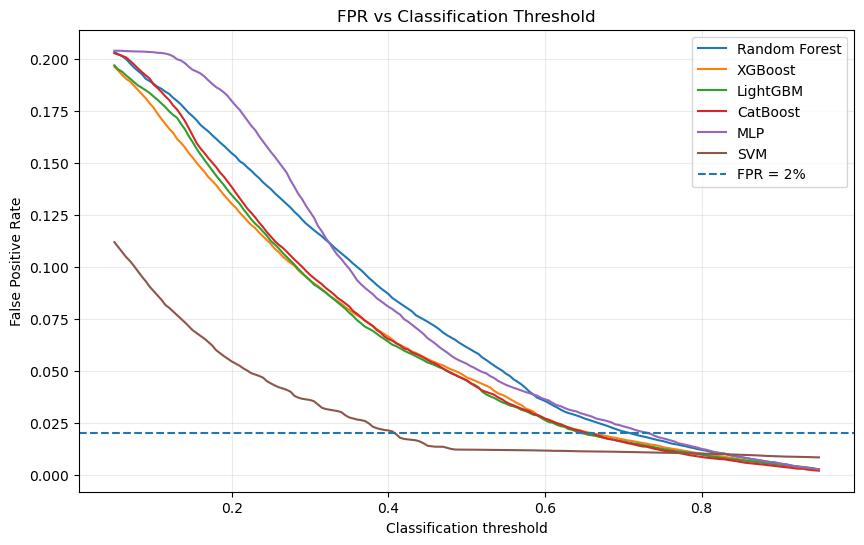

In [14]:
# 17. Inspect threshold curves

fig, ax = plt.subplots(figsize=(10, 6))

for name, result in threshold_results.items():
    ax.plot(
        result["Threshold"],
        result["FPR"],
        label=name
    )

ax.axhline(0.02, linestyle="--", label="FPR = 2%")
ax.set_xlabel("Classification threshold")
ax.set_ylabel("False Positive Rate")
ax.set_title("FPR vs Classification Threshold")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

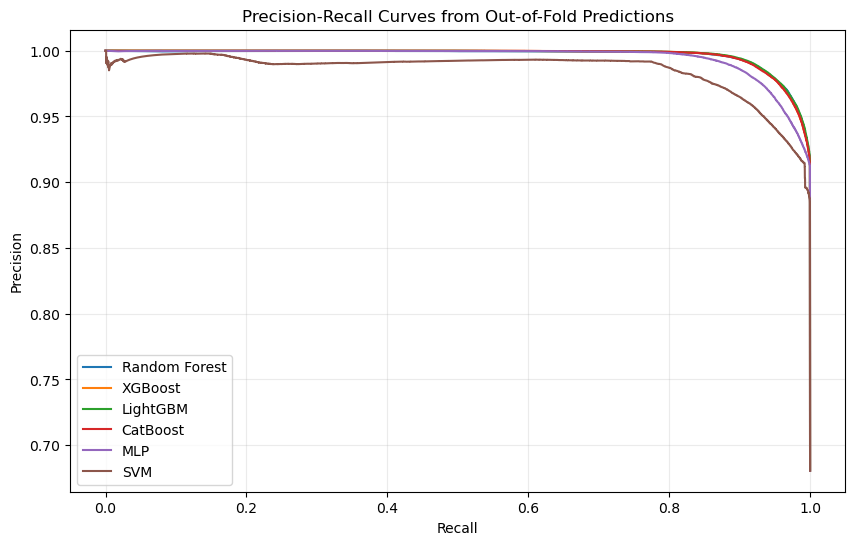

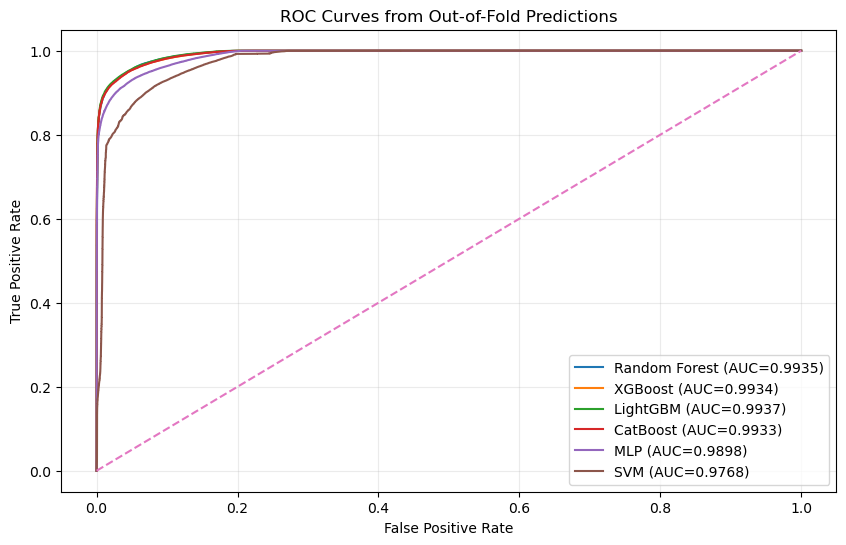

In [15]:
# 18. Precision-recall and ROC curves from out-of-fold predictions

fig, ax = plt.subplots(figsize=(10, 6))

for name, scores in oof_scores.items():
    precision, recall, _ = precision_recall_curve(y_train, scores)
    ax.plot(recall, precision, label=name)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curves from Out-of-Fold Predictions")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


fig, ax = plt.subplots(figsize=(10, 6))

for name, scores in oof_scores.items():
    fpr, tpr, _ = roc_curve(y_train, scores)
    auc = roc_auc_score(y_train, scores)
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.4f})")

ax.plot([0, 1], [0, 1], linestyle="--")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves from Out-of-Fold Predictions")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## 19. Final comparison

This table combines:

- tuning performance
- fresh 5-fold CV performance
- optimized operating threshold

Do not select a final model from the official test set. The test set remains a final frozen evaluation.

In [16]:
# 20. Final training/CV comparison table

tuning_clean = tuning_summary.drop(columns=["Best_Params"]).copy()

final_comparison = (
    threshold_summary
    .merge(tuning_clean, on="Model", how="left")
)

display(
    final_comparison[
        [
            "Model",
            "Threshold",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC-AUC",
            "FPR",
            "FP",
            "FN",
            "Best_CV_F1",
            "Tuning_Time_min"
        ]
    ].sort_values("F1", ascending=False).round(4)
)

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,FPR,FP,FN,Best_CV_F1,Tuning_Time_min
2,LightGBM,0.650,0.9398,0.9899,0.9209,0.9542,0.9937,0.0199,1116.0,9443.0,0.9647,0.5765
0,Random Forest,0.715,0.9381,0.9902,0.9182,0.9528,0.9935,0.0195,1090.0,9763.0,0.9675,1.7034
1,XGBoost,0.665,0.9380,0.9900,0.9182,0.9527,0.9934,0.0197,1105.0,9767.0,0.9637,0.5401
3,CatBoost,0.660,0.9367,0.9899,0.9163,0.9517,0.9933,0.0199,1115.0,9984.0,0.9631,1.8107
4,MLP,0.735,0.9147,0.9896,0.8840,0.9338,0.9898,0.0198,1108.0,13846.0,0.9587,8.5143
5,SVM,0.410,0.8525,0.9885,0.7925,0.8797,0.9768,0.0196,1098.0,24763.0,0.9467,0.2575


## 21. Optional official test evaluation

This section is deliberately separate.

The threshold was selected using training out-of-fold predictions. Once selected, the tuned model is fitted on the **full official training set**, and the frozen threshold is applied exactly once to the official test set.

Nothing from the official test set is used to tune:

- features
- hyperparameters
- thresholds

The models are **not saved**.

In [17]:
# 22. Fit tuned models on the full training data and evaluate once on the official test set

run_official_test = True

if run_official_test:

    official_rows = []

    for _, row in threshold_summary.iterrows():

        name = row["Model"]
        threshold = float(row["Threshold"])

        print("\n" + "=" * 80)
        print("OFFICIAL TEST:", name)
        print("=" * 80)

        model = clone(tuned_models[name])

        if name == "MLP":
            rng = np.random.default_rng(RANDOM_STATE)

            y_array = y_train.to_numpy()
            classes, counts = np.unique(y_array, return_counts=True)
            max_count = counts.max()

            chosen_indices = []
            for cls, count in zip(classes, counts):
                idx = np.flatnonzero(y_array == cls)
                chosen = (
                    rng.choice(idx, size=max_count, replace=True)
                    if count < max_count else idx
                )
                chosen_indices.extend(chosen.tolist())

            chosen_indices = np.asarray(chosen_indices)
            rng.shuffle(chosen_indices)

            X_fit = X_selected.iloc[chosen_indices]
            y_fit = y_train.iloc[chosen_indices]
        else:
            X_fit = X_selected
            y_fit = y_train

        model.fit(X_fit, y_fit)

        test_scores = get_score(model, X_test_selected)

        metrics = metrics_from_scores(
            y_test,
            test_scores,
            threshold=threshold
        )

        metrics["Model"] = name
        metrics["Frozen_Threshold"] = threshold

        official_rows.append(metrics)

        print(pd.DataFrame([metrics]).round(4).to_string(index=False))

    official_test_summary = pd.DataFrame(official_rows)

    display(
        official_test_summary[
            [
                "Model", "Frozen_Threshold", "Accuracy",
                "Precision", "Recall", "F1", "ROC-AUC",
                "FPR", "FP", "FN", "TN", "TP"
            ]
        ].sort_values("F1", ascending=False).round(4)
    )


OFFICIAL TEST: Random Forest
 Accuracy  Precision  Recall     F1  ROC-AUC    FPR   FP   FN    TN    TP         Model  Frozen_Threshold
   0.9354     0.9386  0.9444 0.9415   0.9871 0.0758 2803 2519 34197 42813 Random Forest             0.715

OFFICIAL TEST: XGBoost
 Accuracy  Precision  Recall     F1  ROC-AUC    FPR   FP   FN    TN    TP   Model  Frozen_Threshold
   0.9362     0.9383  0.9464 0.9423   0.9876 0.0763 2823 2429 34177 42903 XGBoost             0.665

OFFICIAL TEST: LightGBM
 Accuracy  Precision  Recall    F1  ROC-AUC    FPR   FP   FN    TN    TP    Model  Frozen_Threshold
    0.937     0.9387  0.9475 0.943   0.9883 0.0759 2807 2381 34193 42951 LightGBM              0.65

OFFICIAL TEST: CatBoost
 Accuracy  Precision  Recall    F1  ROC-AUC    FPR   FP   FN    TN    TP    Model  Frozen_Threshold
   0.9413     0.9425  0.9515 0.947   0.9892 0.0712 2633 2199 34367 43133 CatBoost              0.66

OFFICIAL TEST: MLP
 Accuracy  Precision  Recall     F1  ROC-AUC    FPR   FP   FN   

,Model,Frozen_Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,FPR,FP,FN,TN,TP
3,CatBoost,0.660,0.9413,0.9425,0.9515,0.9470,0.9892,0.0712,2633,2199,34367,43133
2,LightGBM,0.650,0.9370,0.9387,0.9475,0.9430,0.9883,0.0759,2807,2381,34193,42951
1,XGBoost,0.665,0.9362,0.9383,0.9464,0.9423,0.9876,0.0763,2823,2429,34177,42903
0,Random Forest,0.715,0.9354,0.9386,0.9444,0.9415,0.9871,0.0758,2803,2519,34197,42813
4,MLP,0.735,0.9359,0.9500,0.9327,0.9413,0.9871,0.0601,2225,3051,34775,42281
5,SVM,0.410,0.8752,0.9522,0.8143,0.8779,0.9577,0.0501,1855,8416,35145,36916


## 23. Important interpretation

- Hyperparameter tuning happens only on the training data.
- Fresh 5-fold CV evaluates the tuned configurations.
- Threshold optimization uses out-of-fold training predictions.
- The official test set is used only after the model and threshold are frozen.
- No ensemble is created in this notebook.
- No fitted model is saved to disk.
- The SVM is implemented as **LinearSVC** to avoid the extreme runtime of RBF SVC on this dataset.

For the final report, record the exact `Best_Params` from `tuning_summary` and the frozen threshold from `threshold_summary`.

In [18]:
# 24. Compare cross-validation performance with official test performance

cv_mean = (
    cv_fold_table
    .groupby("Model")
    [["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "FPR"]]
    .mean()
    .reset_index()
)

cv_mean = cv_mean.rename(columns={
    "Accuracy": "CV_Accuracy",
    "Precision": "CV_Precision",
    "Recall": "CV_Recall",
    "F1": "CV_F1",
    "ROC-AUC": "CV_ROC-AUC",
    "FPR": "CV_FPR"
})

test_compare = official_test_summary[
    [
        "Model",
        "Frozen_Threshold",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "FPR"
    ]
].copy()

test_compare = test_compare.rename(columns={
    "Accuracy": "Test_Accuracy",
    "Precision": "Test_Precision",
    "Recall": "Test_Recall",
    "F1": "Test_F1",
    "ROC-AUC": "Test_ROC-AUC",
    "FPR": "Test_FPR"
})

cv_test_comparison = cv_mean.merge(
    test_compare,
    on="Model",
    how="inner"
)

# Calculate test - CV differences
for metric in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "FPR"]:
    cv_test_comparison[f"{metric}_Difference"] = (
        cv_test_comparison[f"Test_{metric}"]
        - cv_test_comparison[f"CV_{metric}"]
    )

display(
    cv_test_comparison.sort_values(
        "Test_F1",
        ascending=False
    ).round(4)
)

,Model,CV_Accuracy,CV_Precision,CV_Recall,CV_F1,CV_ROC-AUC,CV_FPR,Frozen_Threshold,Test_Accuracy,Test_Precision,Test_Recall,Test_F1,Test_ROC-AUC,Test_FPR,Accuracy_Difference,Precision_Difference,Recall_Difference,F1_Difference,ROC-AUC_Difference,FPR_Difference
0,CatBoost,0.9516,0.9780,0.9502,0.9639,0.9933,0.0456,0.660,0.9413,0.9425,0.9515,0.9470,0.9892,0.0712,-0.0102,-0.0355,0.0013,-0.0169,-0.0041,0.0256
1,LightGBM,0.9528,0.9781,0.9519,0.9648,0.9937,0.0454,0.650,0.9370,0.9387,0.9475,0.9430,0.9883,0.0759,-0.0158,-0.0395,-0.0044,-0.0218,-0.0054,0.0305
5,XGBoost,0.9519,0.9774,0.9513,0.9642,0.9934,0.0469,0.665,0.9362,0.9383,0.9464,0.9423,0.9876,0.0763,-0.0156,-0.0391,-0.0049,-0.0218,-0.0059,0.0294
3,Random Forest,0.9570,0.9710,0.9657,0.9684,0.9935,0.0614,0.715,0.9354,0.9386,0.9444,0.9415,0.9871,0.0758,-0.0217,-0.0325,-0.0213,-0.0269,-0.0064,0.0143
2,MLP,0.9376,0.9738,0.9334,0.9531,0.9898,0.0535,0.735,0.9359,0.9500,0.9327,0.9413,0.9871,0.0601,-0.0016,-0.0238,-0.0007,-0.0119,-0.0028,0.0066
4,SVM,0.8154,0.9923,0.7345,0.8441,0.9768,0.0122,0.410,0.8752,0.9522,0.8143,0.8779,0.9577,0.0501,0.0599,-0.0401,0.0799,0.0338,-0.0191,0.0379


In [19]:
# 25. Fold-level stability

stability = (
    cv_fold_table
    .groupby("Model")
    [["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "FPR"]]
    .agg(["mean", "std", "min", "max"])
)

display(stability.round(4))

Accuracy                         Precision                  \
                  mean     std     min     max      mean     std     min   
Model                                                                      
CatBoost        0.9516  0.0021  0.9490  0.9541    0.9780  0.0011  0.9766   
LightGBM        0.9528  0.0024  0.9508  0.9561    0.9781  0.0012  0.9767   
MLP             0.9376  0.0031  0.9347  0.9411    0.9738  0.0020  0.9715   
Random Forest   0.9570  0.0019  0.9548  0.9593    0.9710  0.0011  0.9698   
SVM             0.8154  0.0020  0.8136  0.8184    0.9923  0.0003  0.9919   
XGBoost         0.9519  0.0017  0.9503  0.9541    0.9774  0.0011  0.9760   

                       Recall          ...      F1         ROC-AUC          \
                  max    mean     std  ...     min     max    mean     std   
Model                                  ...                                   
CatBoost       0.9795  0.9502  0.0023  ...  0.9620  0.9658  0.9933  0.0004   
LightGBM       0.9799  0.9519  0.0025  ...  0.9634  0.9673  0.9937  0.0005   
MLP            0.9757  0.9334  0.0054  ...  0.9508  0.9558  0.9898  0.0006   
Random Forest  0.9728  0.9657  0.0019  ...  0.9667  0.9700  0.9935  0.0004   
SVM            0.9928  0.7345  0.0031  ...  0.8423  0.8470  0.9768  0.0007   
XGBoost        0.9789  0.9513  0.0016  ...  0.9630  0.9659  0.9934  0.0004   

                                  FPR                          
                  min     max    mean     std     min     max  
Model                                                          
CatBoost       0.9930  0.9939  0.0456  0.0022  0.0426  0.0483  
LightGBM       0.9933  0.9943  0.0454  0.0025  0.0417  0.0482  
MLP            0.9894  0.9906  0.0535  0.0044  0.0494  0.0584  
Random Forest  0.9931  0.9941  0.0614  0.0023  0.0576  0.0638  
SVM            0.9759  0.9779  0.0122  0.0005  0.0113  0.0128  
XGBoost        0.9929  0.9940  0.0469  0.0022  0.0438  0.0497  

[6 rows x 24 columns]

In [20]:
# 26. Default threshold (0.50) vs optimized threshold

threshold_comparison_rows = []

for name, scores in oof_scores.items():

    default_metrics = metrics_from_scores(
        y_train,
        scores,
        threshold=0.50
    )

    optimized_threshold = float(
        threshold_summary.loc[
            threshold_summary["Model"] == name,
            "Threshold"
        ].iloc[0]
    )

    optimized_metrics = metrics_from_scores(
        y_train,
        scores,
        threshold=optimized_threshold
    )

    threshold_comparison_rows.append({
        "Model": name,

        "Default_Threshold": 0.50,
        "Default_F1": default_metrics["F1"],
        "Default_Recall": default_metrics["Recall"],
        "Default_Precision": default_metrics["Precision"],
        "Default_FPR": default_metrics["FPR"],

        "Optimized_Threshold": optimized_threshold,
        "Optimized_F1": optimized_metrics["F1"],
        "Optimized_Recall": optimized_metrics["Recall"],
        "Optimized_Precision": optimized_metrics["Precision"],
        "Optimized_FPR": optimized_metrics["FPR"]
    })

threshold_comparison = pd.DataFrame(threshold_comparison_rows)

display(threshold_comparison.round(4))

,Model,Default_Threshold,Default_F1,Default_Recall,Default_Precision,Default_FPR,Optimized_Threshold,Optimized_F1,Optimized_Recall,Optimized_Precision,Optimized_FPR
0,Random Forest,0.5,0.9684,0.9657,0.9710,0.0614,0.715,0.9528,0.9182,0.9902,0.0195
1,XGBoost,0.5,0.9642,0.9513,0.9774,0.0469,0.665,0.9527,0.9182,0.9900,0.0197
2,LightGBM,0.5,0.9648,0.9519,0.9781,0.0454,0.650,0.9542,0.9209,0.9899,0.0199
3,CatBoost,0.5,0.9639,0.9502,0.9780,0.0456,0.660,0.9517,0.9163,0.9899,0.0199
4,MLP,0.5,0.9532,0.9334,0.9738,0.0535,0.735,0.9338,0.8840,0.9896,0.0198
5,SVM,0.5,0.8441,0.7345,0.9923,0.0122,0.410,0.8797,0.7925,0.9885,0.0196


In [21]:
# 27. FPR shift from CV to official test

fpr_shift = cv_test_comparison[
    [
        "Model",
        "Frozen_Threshold",
        "CV_FPR",
        "Test_FPR",
        "FPR_Difference"
    ]
].copy()

fpr_shift["CV_FPR_percent"] = fpr_shift["CV_FPR"] * 100
fpr_shift["Test_FPR_percent"] = fpr_shift["Test_FPR"] * 100

display(
    fpr_shift[
        [
            "Model",
            "Frozen_Threshold",
            "CV_FPR_percent",
            "Test_FPR_percent",
            "FPR_Difference"
        ]
    ].round(4)
)

,Model,Frozen_Threshold,CV_FPR_percent,Test_FPR_percent,FPR_Difference
0,CatBoost,0.660,4.5607,7.1162,0.0256
1,LightGBM,0.650,4.5375,7.5865,0.0305
2,MLP,0.735,5.3518,6.0135,0.0066
3,Random Forest,0.715,6.1446,7.5757,0.0143
4,SVM,0.410,1.2196,5.0135,0.0379
5,XGBoost,0.665,4.6929,7.6297,0.0294


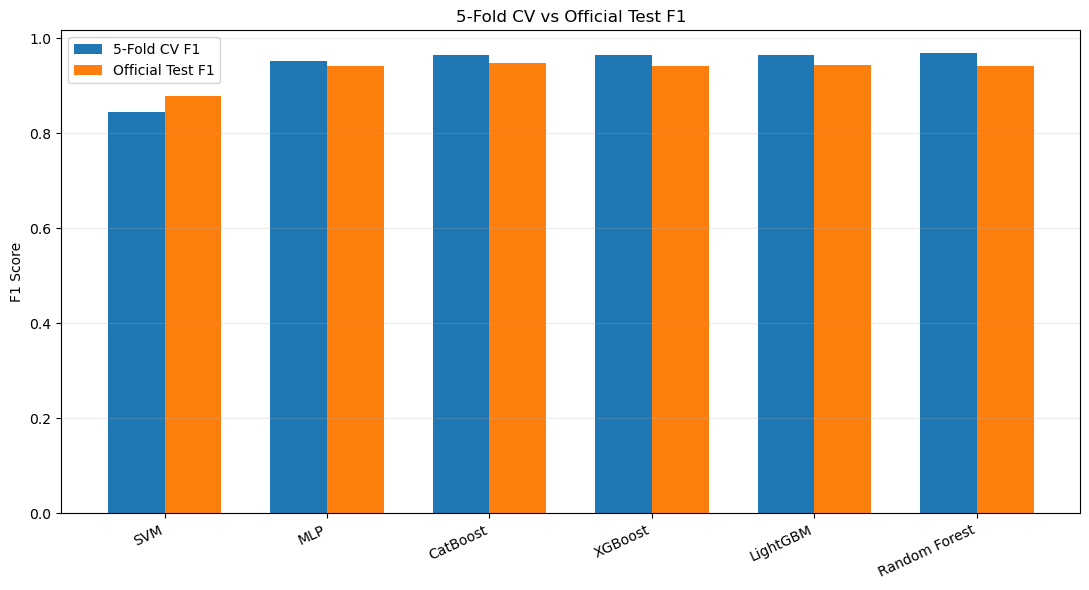

In [22]:
# 28. CV F1 vs Official Test F1

plot_df = cv_test_comparison.sort_values("CV_F1")

x = np.arange(len(plot_df))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    x - width / 2,
    plot_df["CV_F1"],
    width,
    label="5-Fold CV F1"
)

ax.bar(
    x + width / 2,
    plot_df["Test_F1"],
    width,
    label="Official Test F1"
)

ax.set_xticks(x)
ax.set_xticklabels(plot_df["Model"], rotation=25, ha="right")
ax.set_ylabel("F1 Score")
ax.set_title("5-Fold CV vs Official Test F1")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

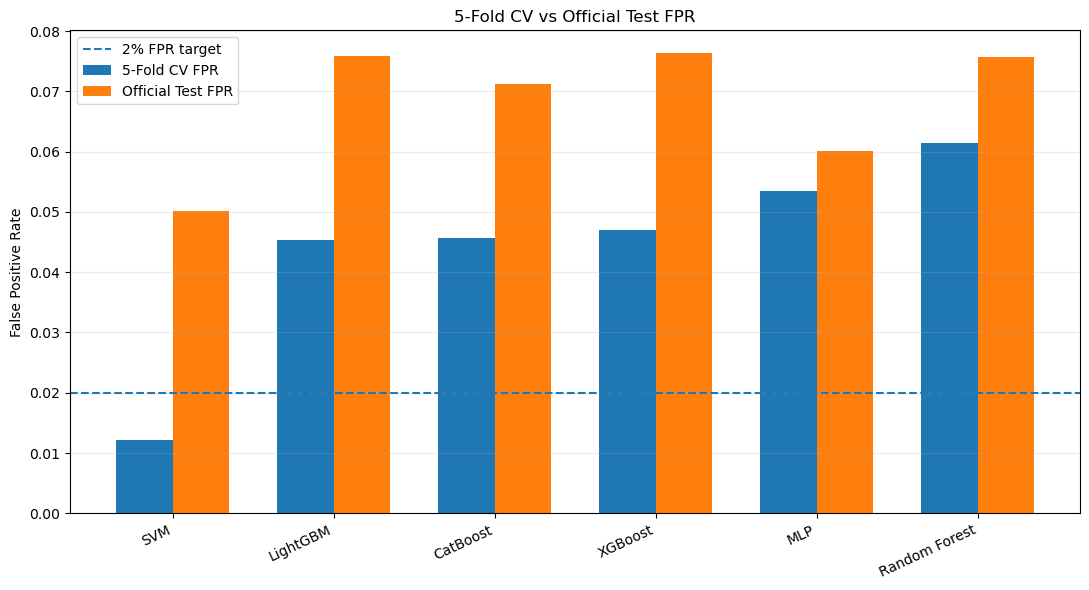

In [23]:
# 29. CV FPR vs Official Test FPR

plot_df = cv_test_comparison.sort_values("CV_FPR")

x = np.arange(len(plot_df))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    x - width / 2,
    plot_df["CV_FPR"],
    width,
    label="5-Fold CV FPR"
)

ax.bar(
    x + width / 2,
    plot_df["Test_FPR"],
    width,
    label="Official Test FPR"
)

ax.axhline(
    0.02,
    linestyle="--",
    label="2% FPR target"
)

ax.set_xticks(x)
ax.set_xticklabels(plot_df["Model"], rotation=25, ha="right")
ax.set_ylabel("False Positive Rate")
ax.set_title("5-Fold CV vs Official Test FPR")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

In [24]:
# 30. Final model report

final_report = official_test_summary[
    [
        "Model",
        "Frozen_Threshold",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "FPR",
        "FP",
        "FN",
        "TN",
        "TP"
    ]
].copy()

final_report = final_report.sort_values(
    "F1",
    ascending=False
).reset_index(drop=True)

print("FINAL OFFICIAL TEST RESULTS")
display(final_report.round(4))

FINAL OFFICIAL TEST RESULTS


,Model,Frozen_Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,FPR,FP,FN,TN,TP
0,CatBoost,0.660,0.9413,0.9425,0.9515,0.9470,0.9892,0.0712,2633,2199,34367,43133
1,LightGBM,0.650,0.9370,0.9387,0.9475,0.9430,0.9883,0.0759,2807,2381,34193,42951
2,XGBoost,0.665,0.9362,0.9383,0.9464,0.9423,0.9876,0.0763,2823,2429,34177,42903
3,Random Forest,0.715,0.9354,0.9386,0.9444,0.9415,0.9871,0.0758,2803,2519,34197,42813
4,MLP,0.735,0.9359,0.9500,0.9327,0.9413,0.9871,0.0601,2225,3051,34775,42281
5,SVM,0.410,0.8752,0.9522,0.8143,0.8779,0.9577,0.0501,1855,8416,35145,36916


Generate official-test predictions

In [26]:
# ============================================================
# FROZEN THRESHOLDS
# ============================================================

model_thresholds = {
    "Random Forest": 0.715,
    "XGBoost": 0.665,
    "LightGBM": 0.650,
    "CatBoost": 0.660,
    "MLP": 0.735,
    "SVM": 0.410
}

test_predictions = {}
test_scores_all = {}

print("Generating official-test predictions...")
print("=" * 70)

for name, tuned_model in tuned_models.items():

    print(f"\nTraining: {name}")

    model = clone(tuned_model)

    # --------------------------------------------------------
    # MLP: random oversampling
    # --------------------------------------------------------
    if name == "MLP":

        rng = np.random.default_rng(RANDOM_STATE)

        y_array_train = y_train.to_numpy()

        classes, counts = np.unique(
            y_array_train,
            return_counts=True
        )

        max_count = counts.max()

        chosen_indices = []

        for cls, count in zip(classes, counts):

            idx = np.flatnonzero(
                y_array_train == cls
            )

            if count < max_count:
                chosen = rng.choice(
                    idx,
                    size=max_count,
                    replace=True
                )
            else:
                chosen = idx

            chosen_indices.extend(
                chosen.tolist()
            )

        chosen_indices = np.asarray(
            chosen_indices
        )

        rng.shuffle(chosen_indices)

        X_fit = X_selected.iloc[chosen_indices]
        y_fit = y_train.iloc[chosen_indices]

    else:

        X_fit = X_selected
        y_fit = y_train

    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    model.fit(X_fit, y_fit)

    # --------------------------------------------------------
    # Continuous scores
    # --------------------------------------------------------

    scores = get_score(
        model,
        X_test_selected
    )

    # --------------------------------------------------------
    # Frozen threshold
    # --------------------------------------------------------

    threshold = model_thresholds[name]

    predictions = (
        scores >= threshold
    ).astype(int)

    test_scores_all[name] = scores
    test_predictions[name] = predictions

    print(
        f"{name}: threshold = {threshold:.3f}"
    )

print("\nAll official-test predictions generated successfully.")

Generating official-test predictions...

Training: Random Forest
Random Forest: threshold = 0.715

Training: XGBoost
XGBoost: threshold = 0.665

Training: LightGBM
LightGBM: threshold = 0.650

Training: CatBoost
CatBoost: threshold = 0.660

Training: MLP
MLP: threshold = 0.735

Training: SVM
SVM: threshold = 0.410

All official-test predictions generated successfully.


In [ ]:
# ============================================================
# ERROR SIMILARITY
# ============================================================

model_names = list(test_predictions.keys())
y_array = y_test.to_numpy()

error_matrix = pd.DataFrame(
    index=model_names,
    columns=model_names,
    dtype=float
)

for model_a in model_names:

    errors_a = test_predictions[model_a] != y_array

    for model_b in model_names:

        errors_b = test_predictions[model_b] != y_array

        intersection = np.sum(errors_a & errors_b)
        union = np.sum(errors_a | errors_b)

        error_matrix.loc[model_a, model_b] = (
            intersection / union if union > 0 else 0
        )

print("Pairwise Error Similarity")
display(error_matrix.round(3))

In [ ]:
# ============================================================
# PREDICTION DISAGREEMENT
# ============================================================

disagreement_matrix = pd.DataFrame(
    index=model_names,
    columns=model_names,
    dtype=float
)

for model_a in model_names:
    for model_b in model_names:

        disagreement_matrix.loc[model_a, model_b] = np.mean(
            test_predictions[model_a] != test_predictions[model_b]
        )

print("Pairwise Prediction Disagreement (%)")

display(
    (disagreement_matrix * 100).round(2)
)

In [ ]:
# ============================================================
# ERROR RECOVERY
# ============================================================

recovery_rows = []

for model_a in model_names:

    pred_a = test_predictions[model_a]
    errors_a = pred_a != y_array

    for model_b in model_names:

        if model_a == model_b:
            continue

        pred_b = test_predictions[model_b]

        recovered = errors_a & (pred_b == y_array)

        total_errors = errors_a.sum()
        recovered_count = recovered.sum()

        recovery_rate = (
            recovered_count / total_errors
            if total_errors > 0
            else 0
        )

        recovery_rows.append({
            "Model_A": model_a,
            "Model_B": model_b,
            "A_Errors": total_errors,
            "B_Recovers_A_Errors": recovered_count,
            "Recovery_Rate": recovery_rate
        })

recovery_df = pd.DataFrame(recovery_rows)

display(
    recovery_df
    .sort_values("Recovery_Rate", ascending=False)
    .round(4)
)

In [ ]:
# ============================================================
# COMPLEMENTARY MODEL PAIRS
# ============================================================

pair_rows = []

for i, model_a in enumerate(model_names):

    for model_b in model_names[i + 1:]:

        pred_a = test_predictions[model_a]
        pred_b = test_predictions[model_b]

        errors_a = pred_a != y_array
        errors_b = pred_b != y_array

        intersection = np.sum(errors_a & errors_b)
        union = np.sum(errors_a | errors_b)

        error_similarity = (
            intersection / union
            if union > 0
            else 0
        )

        disagreement = np.mean(
            pred_a != pred_b
        )

        pair_rows.append({
            "Model_A": model_a,
            "Model_B": model_b,
            "Error_Similarity": error_similarity,
            "Prediction_Disagreement": disagreement
        })

pairwise_complementarity = pd.DataFrame(pair_rows)

display(
    pairwise_complementarity
    .sort_values("Error_Similarity")
    .round(4)
)

In [ ]:
# ============================================================
# SUMMARY
# ============================================================

best_error_pair = pairwise_complementarity.sort_values(
    "Error_Similarity"
).iloc[0]

best_disagreement_pair = pairwise_complementarity.sort_values(
    "Prediction_Disagreement",
    ascending=False
).iloc[0]

print("=" * 70)
print("COMPLEMENTARY ERROR ANALYSIS")
print("=" * 70)

print("\nLowest error similarity:")
print(
    f"{best_error_pair['Model_A']} + "
    f"{best_error_pair['Model_B']}"
)
print(
    f"Error similarity: "
    f"{best_error_pair['Error_Similarity']:.4f}"
)

print("\nHighest prediction disagreement:")
print(
    f"{best_disagreement_pair['Model_A']} + "
    f"{best_disagreement_pair['Model_B']}"
)
print(
    f"Disagreement: "
    f"{best_disagreement_pair['Prediction_Disagreement']:.4f}"
)

print("\nIndividual model performance:")
display(
    official_test_summary[
        ["Model", "F1", "Precision", "Recall", "FPR"]
    ]
    .sort_values("F1", ascending=False)
    .round(4)
)